In [1]:
# Load the higher-resolution LFW data for protocol construction

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_lfw_people


lfw = fetch_lfw_people(
    min_faces_per_person=5,
    color=True,
    resize=1.0,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

gallery_images_per_identity = 3
probe_images_per_identity = 2
random_seed = 42

print(f"Images shape: {images.shape}")
print(f"Number of identities: {len(identity_names)}")
print(f"Gallery images per identity: {gallery_images_per_identity}")
print(f"Probe images per identity: {probe_images_per_identity}")

Images shape: (5985, 125, 94, 3)
Number of identities: 423
Gallery images per identity: 3
Probe images per identity: 2


In [2]:
# Construct a deterministic gallery–probe split

random_generator = np.random.default_rng(random_seed)
split_records = []

for identity_id, identity_name in enumerate(identity_names):
    identity_indices = np.where(labels == identity_id)[0]
    shuffled_indices = random_generator.permutation(identity_indices)

    gallery_indices = shuffled_indices[:gallery_images_per_identity]
    probe_indices = shuffled_indices[
        gallery_images_per_identity:
        gallery_images_per_identity + probe_images_per_identity
    ]

    for enrollment_order, image_index in enumerate(gallery_indices, start=1):
        split_records.append({
            "image_index": image_index,
            "identity_id": identity_id,
            "identity_name": identity_name,
            "split": "gallery",
            "role": "enrollment",
            "sample_order": enrollment_order
        })

    for probe_order, image_index in enumerate(probe_indices, start=1):
        split_records.append({
            "image_index": image_index,
            "identity_id": identity_id,
            "identity_name": identity_name,
            "split": "probe",
            "role": "identification",
            "sample_order": probe_order
        })

gallery_probe_split = pd.DataFrame(split_records)

gallery_probe_split.head()

,image_index,identity_id,identity_name,split,role,sample_order
0,5068,0,Abdullah Gul,gallery,enrollment,1
1,4112,0,Abdullah Gul,gallery,enrollment,2
2,5570,0,Abdullah Gul,gallery,enrollment,3
3,2754,0,Abdullah Gul,probe,identification,1
4,4556,0,Abdullah Gul,probe,identification,2


In [3]:
# Verify the gallery–probe protocol

split_summary = (
    gallery_probe_split
    .groupby(["split", "identity_id"])
    .size()
    .reset_index(name="image_count")
)

print(f"Total protocol images: {len(gallery_probe_split)}")
print(
    f"Gallery images: "
    f"{(gallery_probe_split['split'] == 'gallery').sum()}"
)
print(
    f"Probe images: "
    f"{(gallery_probe_split['split'] == 'probe').sum()}"
)
print(
    f"Gallery identities: "
    f"{gallery_probe_split.loc[gallery_probe_split['split'] == 'gallery', 'identity_id'].nunique()}"
)
print(
    f"Probe identities: "
    f"{gallery_probe_split.loc[gallery_probe_split['split'] == 'probe', 'identity_id'].nunique()}"
)

display(
    gallery_probe_split
    .groupby(["split", "identity_id"])["image_index"]
    .count()
    .value_counts()
    .sort_index()
    .rename("number_of_identities")
    .to_frame()
)

Total protocol images: 2115
Gallery images: 1269
Probe images: 846
Gallery identities: 423
Probe identities: 423


,number_of_identities
image_index,
2,423
3,423


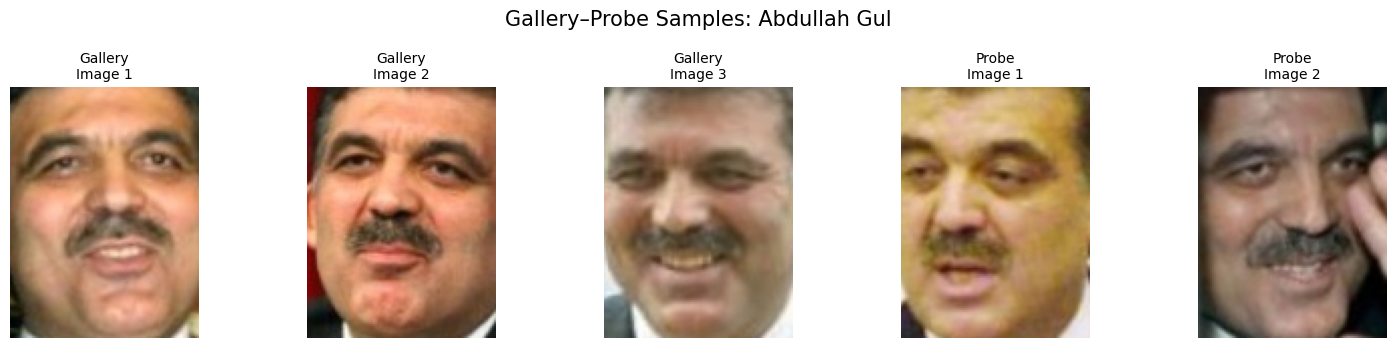

In [4]:
# Visualize the enrollment and probe images for one identity

example_identity_id = gallery_probe_split["identity_id"].iloc[0]
example_records = gallery_probe_split[
    gallery_probe_split["identity_id"] == example_identity_id
]

figure, axes = plt.subplots(1, 5, figsize=(15, 3.5))

for axis, (_, record) in zip(axes, example_records.iterrows()):
    image = images[int(record["image_index"])]

    axis.imshow(image)
    axis.set_title(
        f"{record['split'].capitalize()}\n"
        f"Image {record['sample_order']}",
        fontsize=10
    )
    axis.axis("off")

figure.suptitle(
    f"Gallery–Probe Samples: {example_records['identity_name'].iloc[0]}",
    fontsize=15
)
figure.tight_layout()
plt.show()

In [5]:
# Save the reproducible split metadata to Google Drive

output_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data"
)

output_directory.mkdir(parents=True, exist_ok=True)

split_path = output_directory / "lfw_gallery_probe_split.csv"
gallery_probe_split.to_csv(split_path, index=False)

print(f"Saved split metadata to:\n{split_path}")

Saved split metadata to:
/content/drive/MyDrive/Colab Notebooks/face_degradation/data/lfw_gallery_probe_split.csv
